# Milestone 4 - Machine Learning Models

**Question (from Milestone 3):** at the moment a flight leaves the gate late, will it still arrive **15+ minutes late**?

**Data:** the train / test files saved by `milestone_3_preprocessing.ipynb`. They hold 80,000 training flights and 20,000 test flights, 66 numeric input columns, scaled on train only, with no overlap.

Plan of this notebook:
1. Load the data
2. Which models we try, and why
3. How we compare them fairly (cross-validation + metrics)
4. Baselines: the scores any model must beat
5. Train and tune each model with cross-validation
6. Compare all models and choose the final one
7. Overfitting check (train vs validation, learning curve)
8. Final result on the test set
9. Explaining the model (which features drive delays, and one flight explained)
10. Error analysis: where does the model go wrong?
11. Extra experiment: what if we don't know the departure delay?
12. Extra: predicting how many minutes late (regression)
13. Example predictions
14. Challenges, limitations and next steps

## 1. Load the data

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, KFold, cross_validate, learning_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 4)

X_train = pd.read_csv('data/X_train.csv')
X_test = pd.read_csv('data/X_test.csv')
y_train_all = pd.read_csv('data/y_train.csv')
y_test_all = pd.read_csv('data/y_test.csv')
train_details = pd.read_csv('data/train_details.csv')
test_details = pd.read_csv('data/test_details.csv')

y_train = y_train_all['IsDelayed']
y_test = y_test_all['IsDelayed']

print('train:', X_train.shape, '| test:', X_test.shape)
print('delayed share train:', round(y_train.mean() * 100, 1), '% | test:', round(y_test.mean() * 100, 1), '%')

train: (80000, 66) | test: (20000, 66)
delayed share train: 64.8 % | test: 64.8 %


## 2. Which models we try, and why

| Model | Why we try it |
|---|---|
| **Baseline: always "delayed"** | The simplest possible "model". Any real model must beat it, otherwise it learned nothing |
| **Baseline: simple rule** "left 15+ min late, so it will arrive late" | The EDA showed departure delay decides most of the result. If a model can't beat this one-line rule, it isn't worth using |
| **Logistic Regression** | Simple, fast, and easy to explain: every feature gets a weight that pushes a flight toward "delayed" or "on time". It is a good fit for our explainability goal |
| **KNN** | Predicts from the most similar past flights. A very different idea from the others, so it is a good comparison. It needs scaled data, which we have |
| **Decision Tree** | Learns if/else rules (e.g. "departure delay > 25 min and evening") that are easy to read. It can capture non-linear patterns like the hour curve |
| **Random Forest** | Many trees voting together. Usually more accurate and more stable than a single tree, and it gives feature importances |

**Not used:** K-Means clustering, because our question has a known answer for every flight (delayed or not), so it is a supervised problem. K-Means is for finding groups when there are no labels.

## 3. How we compare models fairly

**Cross-validation:** we split the **training set** into 5 parts (folds). Each model is trained on 4 parts and scored on the 5th, five times, and we report the average and the spread (std).
**Why:** one single split can be lucky or unlucky, while 5 folds give a more trustworthy score. All models use **exactly the same 5 folds** (`random_state=42`), so the comparison is fair.
**The test set is not touched** until the final model is chosen (section 8). If we used it to choose, it would no longer be "new" data.

**Metrics** (the "delayed" class is the positive class):
- **Accuracy:** % of flights predicted correctly. Easy to understand, but with 65% delayed flights a model that always says "delayed" already gets 65%.
- **Precision:** of the flights we flag as "will be delayed", how many really were. Low precision means many false alarms (e.g. rebooking passengers who didn't need it).
- **Recall:** of the flights that really were delayed, how many we caught. Low recall means missed delays (passengers miss connections without warning).
- **F1:** a balance of precision and recall. **This is our main metric**, because for a dispatch team both kinds of mistake cost money.
- **ROC AUC:** how well the model *ranks* flights from least to most likely delayed (0.5 = random guessing, 1.0 = perfect). It is useful because the airline can choose its own alarm threshold.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

def run_cv(model, X=X_train):
    scores = cross_validate(model, X, y_train, cv=cv, scoring=metrics)
    result = {}
    for m in metrics:
        result[m] = scores['test_' + m].mean()
        result[m + '_std'] = scores['test_' + m].std()
    return result

results = {}   # model name -> cross-validation scores

## 4. Baselines

**Why:** the baseline scores tell us what "good" means for this problem. Without them, 83% accuracy might sound great or terrible, and we can't tell which.

The rule baseline doesn't learn anything, so we just score it on the same 5 validation folds as the models.

In [3]:
results['Baseline: always delayed'] = run_cv(DummyClassifier(strategy='most_frequent'))

# rule: predict "delayed" when the flight left 15+ minutes late
rule_scores = {m: [] for m in metrics}
for train_idx, val_idx in cv.split(X_train, y_train):
    true = y_train.iloc[val_idx]
    pred = (train_details['DepDelay'].iloc[val_idx] >= 15).astype(int)
    rule_scores['accuracy'].append(accuracy_score(true, pred))
    rule_scores['precision'].append(precision_score(true, pred))
    rule_scores['recall'].append(recall_score(true, pred))
    rule_scores['f1'].append(f1_score(true, pred))
    rule_scores['roc_auc'].append(roc_auc_score(true, pred))

results['Baseline: rule DepDelay >= 15'] = {}
for m in metrics:
    results['Baseline: rule DepDelay >= 15'][m] = np.mean(rule_scores[m])
    results['Baseline: rule DepDelay >= 15'][m + '_std'] = np.std(rule_scores[m])

pd.DataFrame(results).T[metrics].round(4)

,accuracy,precision,recall,f1,roc_auc
Baseline: always delayed,0.6484,0.6484,1.0000,0.7867,0.5000
Baseline: rule DepDelay >= 15,0.8216,0.8418,0.8926,0.8665,0.7917


**Result:**
- Always saying "delayed" gives **64.8% accuracy and F1 0.787**, but it is useless: it never says "on time" (ROC AUC 0.5 = no skill).
- The one-line rule "left 15+ min late, so it will arrive late" already gives **82.2% accuracy and F1 0.867**. This is the real bar to beat. Its ROC AUC is low (0.79) only because a rule gives yes/no answers and no probabilities, so it can't rank flights.

## 5. Train and tune each model

For each model we try a few values of its most important setting and keep the one with the best **cross-validated F1**.
**Why only a few values:** the goal is a fair comparison between model types, not squeezing out the last 0.1%. A small, clear search is easier to explain and keeps the notebook fast to rerun.

### 5.1 Logistic Regression

**Setting:** `C` controls how strongly the weights are held back (smaller C = simpler model, less risk of overfitting).

In [4]:
def tune(make_model, values, name):
    rows = []
    for v in values:
        start = time.time()
        scores = run_cv(make_model(v))
        scores['value'] = v
        scores['seconds'] = round(time.time() - start, 1)
        rows.append(scores)
    table = pd.DataFrame(rows).set_index('value')
    print(table[['accuracy', 'f1', 'f1_std', 'roc_auc', 'seconds']].round(4))
    best_value = table['f1'].idxmax()
    print('best value:', best_value)
    results[name] = table.loc[best_value].drop(['seconds']).to_dict()
    return best_value

best_C = tune(lambda c: LogisticRegression(C=c, max_iter=1000), [0.01, 0.1, 1, 10], 'Logistic Regression')

       accuracy      f1  f1_std  roc_auc  seconds
value                                            
0.01     0.8334  0.8724  0.0004   0.9123      1.5
0.10     0.8338  0.8726  0.0009   0.9124      1.5
1.00     0.8339  0.8727  0.0008   0.9124      1.6
10.00    0.8340  0.8727  0.0008   0.9124      1.5
best value: 10.0


**Result:** `C` barely changes anything (all F1 values are within 0.0003). The highest value is C = 10, so we keep it. This tells us the model is not overfitting, because holding the weights back more doesn't help.

### 5.2 KNN

**Setting:** `n_neighbors` (k), the number of similar flights that vote. A small k follows the training data very closely (risk of overfitting), while a big k gives smoother predictions.

In [5]:
best_k = tune(lambda k: KNeighborsClassifier(n_neighbors=k, n_jobs=-1), [5, 15, 31, 51], 'KNN')

       accuracy      f1  f1_std  roc_auc  seconds
value                                            
5        0.7935  0.8415  0.0016   0.8634     38.2
15       0.8165  0.8589  0.0015   0.8979    112.8
31       0.8270  0.8664  0.0007   0.9082     40.4
51       0.8298  0.8685  0.0005   0.9108    123.1
best value: 51


**Result:** a bigger k is clearly better: F1 goes from 0.842 (k=5) to 0.869 (k=51). With a small k the model copies a few noisy neighbors, so it overfits. The score might still go up a little with an even bigger k, but each run already takes about 2 minutes (KNN compares every flight with 64,000 others), so we stop at 51. Slowness is a real drawback of KNN on big data.

### 5.3 Decision Tree

**Setting:** `max_depth`, how many questions the tree may ask in a row. A very deep tree memorizes the training flights (overfitting), while a very shallow one is too simple (underfitting).

In [6]:
best_depth = tune(lambda d: DecisionTreeClassifier(max_depth=d, random_state=42), [3, 5, 8, 12, 20], 'Decision Tree')

       accuracy      f1  f1_std  roc_auc  seconds
value                                            
3        0.8316  0.8657  0.0051   0.9054      4.9
5        0.8350  0.8704  0.0010   0.9123      8.4
8        0.8318  0.8672  0.0011   0.9091      3.9
12       0.8199  0.8578  0.0011   0.8813      2.6
20       0.7945  0.8386  0.0019   0.8057      2.8
best value: 5


**Result:** this is overfitting in action. A depth of **5 is best (F1 0.870)**. Deeper trees get *worse* on the validation folds (depth 20: F1 0.839, AUC 0.81), because they start memorizing individual training flights instead of general patterns. Depth 3 is a bit too simple (underfitting).

### 5.4 Random Forest

**Settings:** 200 trees (enough for stable votes, more only adds time), and we tune `max_depth` like for the single tree.

In [7]:
best_rf_depth = tune(lambda d: RandomForestClassifier(n_estimators=200, max_depth=d, n_jobs=-1, random_state=42),
                     [10, 15, 20], 'Random Forest')

       accuracy      f1  f1_std  roc_auc  seconds
value                                            
10       0.8358  0.8681  0.0006   0.9108     13.6
15       0.8368  0.8694  0.0009   0.9147     19.6
20       0.8353  0.8690  0.0003   0.9145     54.3
best value: 15


**Result:** depth 15 is best (F1 0.869, AUC 0.915). Depth 20 is no better and takes about 6 times longer.

## 6. Compare all models and choose the final one

In [8]:
comparison = pd.DataFrame(results).T
comparison = comparison[metrics + ['f1_std', 'roc_auc_std']].sort_values('f1', ascending=False)
comparison.round(4)

,accuracy,precision,recall,f1,roc_auc,f1_std,roc_auc_std
Logistic Regression,0.8340,0.8676,0.8780,0.8727,0.9124,0.0008,0.0008
Decision Tree,0.8350,0.8868,0.8547,0.8704,0.9123,0.0010,0.0003
Random Forest,0.8368,0.9035,0.8378,0.8694,0.9147,0.0009,0.0006
KNN,0.8298,0.8704,0.8666,0.8685,0.9108,0.0005,0.0007
Baseline: rule DepDelay >= 15,0.8216,0.8418,0.8926,0.8665,0.7917,0.0006,0.0009
Baseline: always delayed,0.6484,0.6484,1.0000,0.7867,0.5000,0.0000,0.0000


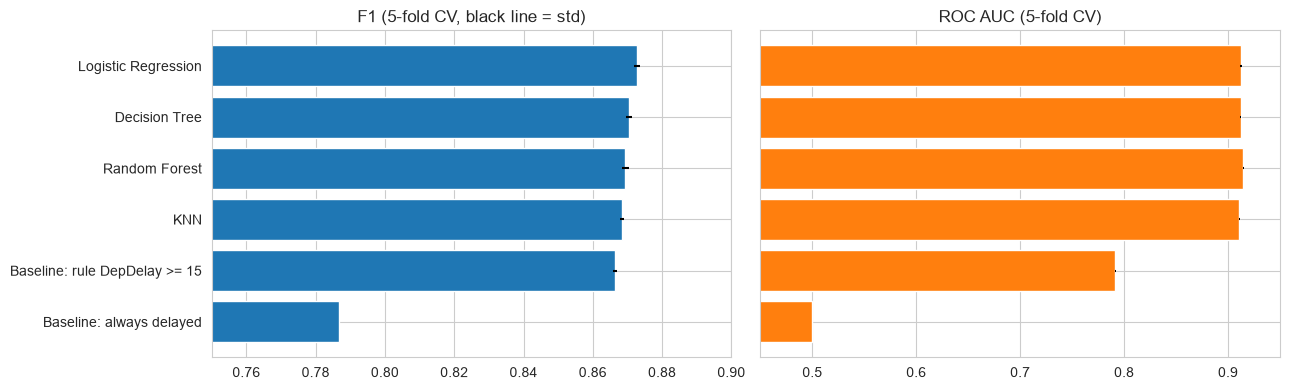

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = comparison.index

axes[0].barh(names, comparison['f1'], xerr=comparison['f1_std'], color='tab:blue')
axes[0].set_xlim(0.75, 0.9)
axes[0].set_title('F1 (5-fold CV, black line = std)')
axes[0].invert_yaxis()

axes[1].barh(names, comparison['roc_auc'], xerr=comparison['roc_auc_std'], color='tab:orange')
axes[1].set_xlim(0.45, 0.95)
axes[1].set_title('ROC AUC (5-fold CV)')
axes[1].invert_yaxis()
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

**Comparison (5-fold cross-validation on the training set):**
- All four real models **beat both baselines**, so they learned something beyond the simple rule.
- The four models are **close together** (F1 between 0.869 and 0.873). This makes sense: the EDA showed that departure delay decides most of the outcome, and every model learns that.
- **Logistic Regression has the best F1 (0.8727)**. Random Forest has the best accuracy (0.837) and AUC (0.915), but only by about 0.3 points of accuracy and 0.002 of AUC. Random Forest also has high precision (0.90) but lower recall (0.84), which means it misses more of the delayed flights.

**Final model: Logistic Regression**, because:
1. **Best F1**, our main metric, and the difference to the next model (0.002) is about 2-3 times the fold-to-fold spread (std about 0.001), so it is consistent and not luck.
2. **No overfitting** (checked in section 7).
3. **Fast**: about 2 seconds for 5-fold CV, against about 22 s for Random Forest and about 2 minutes for KNN. Retraining every day would be easy.
4. **Explainable**: each input has one weight, so we can show a dispatcher exactly *why* a flight was flagged (section 9). That is the main goal of our XAI project.

We keep the Random Forest as the second-best model and show it next to Logistic Regression on the test ROC curve.

## 7. Overfitting check

**Why:** a model can look good in cross-validation but still be memorizing. We compare its score on the data it was trained on with its cross-validated score. A big gap means overfitting. We also draw a **learning curve**, which shows how the score changes as the model gets more training data.

In [10]:
final_model = LogisticRegression(C=best_C, max_iter=1000)
final_model.fit(X_train, y_train)

train_f1 = f1_score(y_train, final_model.predict(X_train))
print('F1 on the training data itself:', round(train_f1, 4))
print('F1 in cross-validation        :', round(results['Logistic Regression']['f1'], 4))
print('gap:', round(train_f1 - results['Logistic Regression']['f1'], 4))

# same check for the Random Forest, to compare
rf_check = RandomForestClassifier(n_estimators=200, max_depth=best_rf_depth, n_jobs=-1, random_state=42)
rf_check.fit(X_train, y_train)
rf_train_f1 = f1_score(y_train, rf_check.predict(X_train))
print()
print('Random Forest F1 on training data:', round(rf_train_f1, 4), '| in CV:', round(results['Random Forest']['f1'], 4),
      '| gap:', round(rf_train_f1 - results['Random Forest']['f1'], 4))

F1 on the training data itself: 0.873
F1 in cross-validation        : 0.8727
gap: 0.0003



Random Forest F1 on training data: 0.8934 | in CV: 0.8694 | gap: 0.024


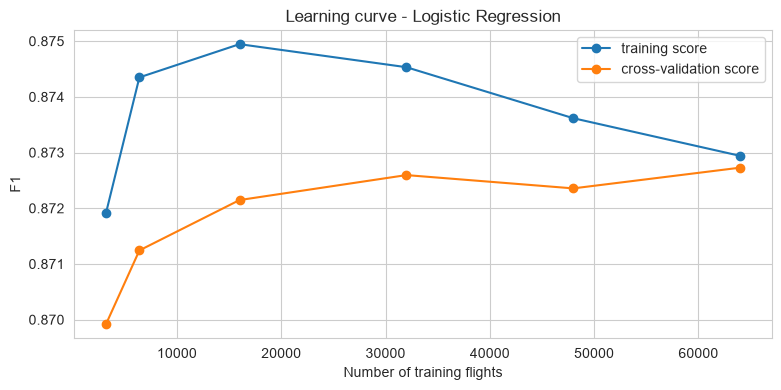

 train size  train F1  CV F1
       3200    0.8719 0.8699
       6400    0.8743 0.8712
      16000    0.8749 0.8721
      32000    0.8745 0.8726
      48000    0.8736 0.8724
      64000    0.8729 0.8727


In [11]:
sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(C=best_C, max_iter=1000), X_train, y_train,
    train_sizes=[0.05, 0.1, 0.25, 0.5, 0.75, 1.0], cv=cv, scoring='f1')

plt.plot(sizes, train_scores.mean(axis=1), marker='o', label='training score')
plt.plot(sizes, val_scores.mean(axis=1), marker='o', label='cross-validation score')
plt.title('Learning curve - Logistic Regression')
plt.xlabel('Number of training flights')
plt.ylabel('F1')
plt.legend()
plt.show()

print(pd.DataFrame({'train size': sizes, 'train F1': train_scores.mean(axis=1).round(4),
                    'CV F1': val_scores.mean(axis=1).round(4)}).to_string(index=False))

**Result:**
- **Logistic Regression:** F1 on its own training data (0.873) is practically the same as in cross-validation (0.8727, gap 0.0003). It is **not overfitting**.
- **Random Forest:** a gap of 0.024 (0.893 vs 0.869). It fits the training flights noticeably better than new ones, which is a mild form of overfitting.
- **Learning curve:** the training and cross-validation lines are very close at every size, and the CV score is almost flat after about 16,000 flights (0.8721 -> 0.8727). So **more data would not help this model much**. To do better we would need **new information** (better features), not more rows. This is also a good argument that our 100,000-flight sample was big enough.

## 8. Final result on the test set

**Why only now:** the test set has not been used for any decision so far. This is the one honest estimate of how the model would do on new flights. We show the baselines next to it on the same test flights.

In [12]:
test_pred = final_model.predict(X_test)
test_prob = final_model.predict_proba(X_test)[:, 1]
rule_pred = (test_details['DepDelay'] >= 15).astype(int)
always_pred = np.ones(len(y_test), dtype=int)

test_table = pd.DataFrame({
    'Logistic Regression (final)': [accuracy_score(y_test, test_pred), precision_score(y_test, test_pred),
                                    recall_score(y_test, test_pred), f1_score(y_test, test_pred), roc_auc_score(y_test, test_prob)],
    'Rule DepDelay >= 15': [accuracy_score(y_test, rule_pred), precision_score(y_test, rule_pred),
                            recall_score(y_test, rule_pred), f1_score(y_test, rule_pred), roc_auc_score(y_test, rule_pred)],
    'Always delayed': [accuracy_score(y_test, always_pred), precision_score(y_test, always_pred),
                       recall_score(y_test, always_pred), f1_score(y_test, always_pred), 0.5],
}, index=metrics)
print('Cross-validated F1 of the final model:', round(results['Logistic Regression']['f1'], 4))
test_table.round(4)

Cross-validated F1 of the final model: 0.8727


,Logistic Regression (final),Rule DepDelay >= 15,Always delayed
accuracy,0.8344,0.8216,0.6484
precision,0.8691,0.8423,0.6484
recall,0.8765,0.8919,1.0000
f1,0.8728,0.8664,0.7867
roc_auc,0.9139,0.7920,0.5000


              precision    recall  f1-score   support

 not delayed      0.769     0.757     0.763      7033
     delayed      0.869     0.877     0.873     12967

    accuracy                          0.834     20000
   macro avg      0.819     0.817     0.818     20000
weighted avg      0.834     0.834     0.834     20000



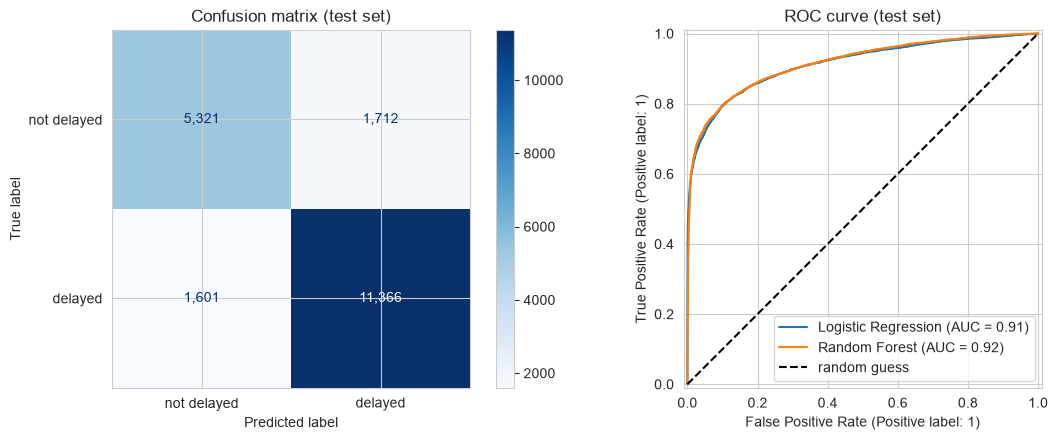

In [13]:
print(classification_report(y_test, test_pred, target_names=['not delayed', 'delayed'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=['not delayed', 'delayed'],
                                        cmap='Blues', values_format=',', ax=axes[0])
axes[0].set_title('Confusion matrix (test set)')

RocCurveDisplay.from_predictions(y_test, test_prob, name='Logistic Regression', ax=axes[1])
rf_prob = rf_check.predict_proba(X_test)[:, 1]
RocCurveDisplay.from_predictions(y_test, rf_prob, name='Random Forest', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='random guess')
axes[1].set_title('ROC curve (test set)')
axes[1].legend()
plt.tight_layout()
plt.show()

**Final test result (20,000 flights the model has never seen):**
- **Accuracy 83.4%, F1 0.873, ROC AUC 0.914**. These are almost identical to the cross-validation scores (F1 0.8727), so the CV estimate was honest.
- Against the rule baseline on the same flights: **+1.3 points accuracy** (83.4% vs 82.2%) and +0.006 F1. The model also gives a **probability** for each flight (AUC 0.91 vs 0.79), so the airline can choose how cautious to be, which the rule can't do.
- **Confusion matrix:** out of 12,967 delayed flights, 11,366 were caught and 1,601 were missed. 1,712 flights were flagged but arrived on time (false alarms). The two kinds of mistake are about equally common.
- The model is better at the "delayed" class (F1 0.87) than at the "not delayed" class (F1 0.76), partly because there are fewer "not delayed" flights to learn from.

**Honest note:** the improvement over the simple rule is real but small. Most of the predictive power comes from the departure delay itself.

## 9. Explaining the model

This is the "XAI" part of the project: not only *that* a flight will be late, but *why*.

### 9.1 Global view: which features push toward "delayed"?

In Logistic Regression each feature has a weight (coefficient). A positive weight pushes a flight toward "delayed", and a negative weight pushes it toward "on time". Numeric features are scaled, so their weight is "per one standard deviation". One-hot features are 0/1, so their weight is the effect of *being* that airline / airport / season.

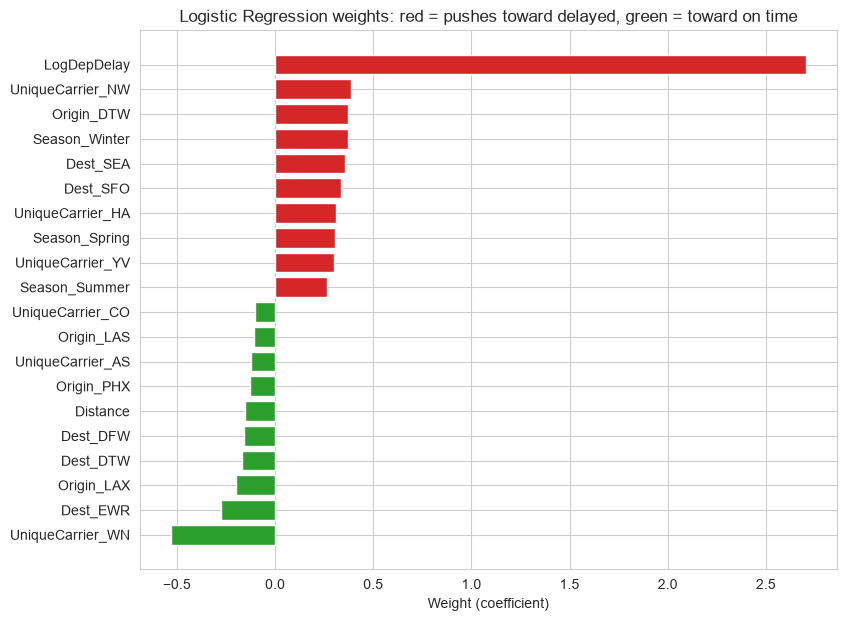

weights of the 3 numeric features:
LogDepDelay    2.702
DepHour       -0.046
Distance      -0.155
dtype: float64

season weights:
Season_Fall      0.061
Season_Summer    0.265
Season_Spring    0.307
Season_Winter    0.373
dtype: float64


In [14]:
coefs = pd.Series(final_model.coef_[0], index=X_train.columns).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])

plt.figure(figsize=(9, 7))
colors = ['tab:green' if v < 0 else 'tab:red' for v in top]
plt.barh(top.index, top.values, color=colors)
plt.title('Logistic Regression weights: red = pushes toward delayed, green = toward on time')
plt.xlabel('Weight (coefficient)')
plt.show()

print('weights of the 3 numeric features:')
print(coefs[['LogDepDelay', 'DepHour', 'Distance']].round(3))
print()
print('season weights:')
print(coefs[[c for c in coefs.index if c.startswith('Season_')]].round(3))

**What the weights say:**
- **Departure delay has by far the biggest weight (2.70).** Every other weight is below 0.6.
- **Airline:** Southwest (WN) has the strongest "on time" weight (-0.53). Northwest (NW) and Mesa (YV) push toward delayed. This matches the EDA.
- **Airports:** departing Detroit (DTW) pushes toward delayed, while departing Phoenix (PHX), Las Vegas (LAS) and Los Angeles (LAX) push toward on time, the same warm-dry-vs-busy-cold pattern as in the EDA.
- **Season:** Winter has the highest season weight and Fall the lowest, as in the EDA.
- **Departure hour has a tiny weight (about -0.05)** even though the EDA showed evening flights are delayed more. This is because the evening effect is already *inside* the departure delay: evening flights leave later because of the domino effect. Once the model knows the departure delay, the hour adds almost nothing.

**Careful:** a weight shows the effect of an input *after the other inputs are taken into account*, so some weights look surprising (for example, arriving at Newark, EWR, has a negative weight although Newark is a busy airport). Weights describe what the model learned from this data. They are **not proof of cause**.

### 9.2 Permutation importance: how much does each original input matter?

The weights above are split over 63 one-hot columns, so we can't directly say how much "the airline" matters overall. **Permutation importance** answers that: we shuffle one input (for example all airline columns together) on the test set and measure how much the F1 drops. A big drop means the model really depends on that input.
**Why this method:** it works for any model and measures importance on data the model has never seen.

Departure delay        0.2148
Airline                0.0028
Origin airport         0.0008
Destination airport    0.0003
Season                 0.0003
Distance               0.0002
Day of week            0.0001
Departure hour        -0.0000
dtype: float64


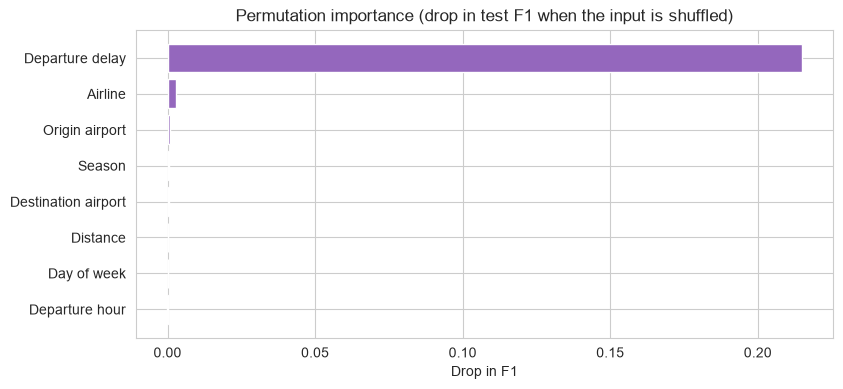

In [15]:
# group the one-hot columns back into the 8 original inputs
groups = {
    'Departure delay': ['LogDepDelay'],
    'Departure hour': ['DepHour'],
    'Distance': ['Distance'],
    'Season': [c for c in X_test.columns if c.startswith('Season_')],
    'Day of week': [c for c in X_test.columns if c.startswith('DayOfWeek_')],
    'Airline': [c for c in X_test.columns if c.startswith('UniqueCarrier_')],
    'Origin airport': [c for c in X_test.columns if c.startswith('Origin_')],
    'Destination airport': [c for c in X_test.columns if c.startswith('Dest_')],
}

base_f1 = f1_score(y_test, final_model.predict(X_test))
rng = np.random.default_rng(42)
importance = {}
for name, cols in groups.items():
    drops = []
    for repeat in range(5):
        shuffled = X_test.copy()
        order = rng.permutation(len(shuffled))
        shuffled[cols] = shuffled[cols].values[order]   # shuffle the whole group together
        drops.append(base_f1 - f1_score(y_test, final_model.predict(shuffled)))
    importance[name] = np.mean(drops)

importance = pd.Series(importance).sort_values()
print((importance).round(4).sort_values(ascending=False))

plt.barh(importance.index, importance.values, color='tab:purple')
plt.title('Permutation importance (drop in test F1 when the input is shuffled)')
plt.xlabel('Drop in F1')
plt.show()

**Result:** shuffling the **departure delay drops the test F1 by about 0.21**. Shuffling the airline drops it by only about 0.003, and every other input by less than 0.001. Departure hour shows practically zero importance, for the reason explained above.

**Business meaning:** for a flight that has *already* left late, the single most useful thing to know is how late it left. The airline and the airports change the risk a little, and the time and day hardly at all once the departure delay is known.

### 9.3 One flight explained

**Why:** a dispatcher doesn't need the whole model, they need to know why *this* flight is flagged.

**How:** we compare the flight with an "average flight" (the average value of every input in the training data). For Logistic Regression each input's contribution is simply: weight x (this flight's value - average value). The contributions add up exactly to the difference between this flight's score and the average flight's score, so nothing is hidden.

We pick the flight the model is most worried about among flights that left only 15-25 minutes late, because that is where the decision is hard (section 10 shows why).

flight details: {'FlightID': 320201, 'DepDelay': 24, 'UniqueCarrier': 'NW', 'Origin': 'DTW', 'DepHour': 7}
its one-hot inputs: ['Season_Winter', 'DayOfWeek_2', 'UniqueCarrier_NW', 'Origin_DTW', 'Dest_MCO']
actual arrival delay: 97.0 min

average flight probability : 81.3 %
this flight probability    : 90.5 %  (model says 90.5 %)

contribution of each input (positive = toward delayed):
Airline                0.423
Origin airport         0.310
Destination airport    0.166
Season                 0.097
Departure hour         0.080
Day of week            0.031
Distance              -0.053
Departure delay       -0.272
dtype: float64


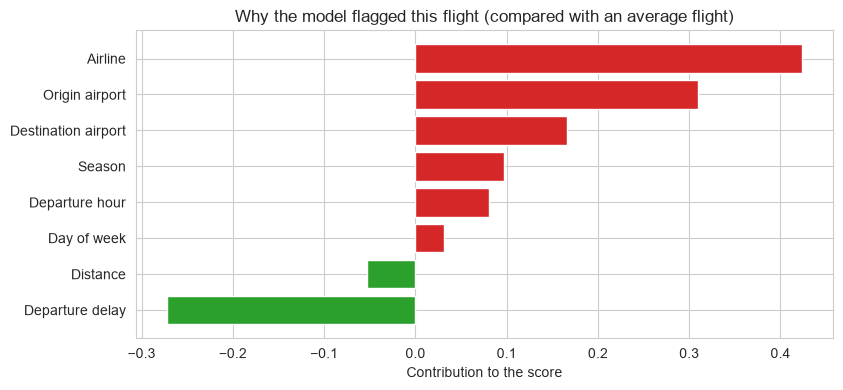

In [16]:
# candidates: left 15-25 min late, flagged as delayed, and really delayed
candidates = test_details[(test_pred == 1) & (y_test.values == 1) & (test_details['DepDelay'].between(15, 25))]
i = candidates.index[np.argmax(test_prob[candidates.index])]

average_flight = X_train.mean()
contrib = (X_test.loc[i] - average_flight) * final_model.coef_[0]
contrib_grouped = pd.Series({name: contrib[cols].sum() for name, cols in groups.items()}).sort_values()

base_score = final_model.intercept_[0] + (average_flight * final_model.coef_[0]).sum()
flight_score = base_score + contrib_grouped.sum()

print('flight details:', test_details.loc[i].to_dict())
print('its one-hot inputs:', [c for c in X_test.columns if c not in ['LogDepDelay', 'DepHour', 'Distance'] and X_test.loc[i, c] == 1])
print('actual arrival delay:', y_test_all.loc[i, 'ArrDelay'], 'min')
print()
print('average flight probability :', round(100 / (1 + np.exp(-base_score)), 1), '%')
print('this flight probability    :', round(100 / (1 + np.exp(-flight_score)), 1), '%  (model says', round(test_prob[i] * 100, 1), '%)')
print()
print('contribution of each input (positive = toward delayed):')
print(contrib_grouped.round(3).sort_values(ascending=False))

colors = ['tab:green' if v < 0 else 'tab:red' for v in contrib_grouped]
plt.barh(contrib_grouped.index, contrib_grouped.values, color=colors)
plt.title('Why the model flagged this flight (compared with an average flight)')
plt.xlabel('Contribution to the score')
plt.show()

**Reading the explanation:** this Northwest flight from Detroit to Orlando left only **24 minutes late** on a winter morning. That is a *lower* departure delay than the average late flight, so the departure delay actually pushes it slightly toward "on time" (negative bar). But the **airline (Northwest)**, the **origin (Detroit)** and the **destination (Orlando)** push it strongly toward delayed, so the model gives it a **90.5% chance** of arriving 15+ minutes late. In reality it arrived **97 minutes late**.

This is the kind of explanation a dispatcher can act on: *"this flight is risky not because of its departure delay, but because of where and with whom it flies"*.

## 10. Error analysis: where does the model go wrong?

**Why:** an overall score hides where the model is weak. Knowing *which* flights it gets wrong tells the airline when to trust it and tells us what to improve.

In [17]:
check = test_details.copy()
check['actual'] = y_test.values
check['predicted'] = test_pred
check['correct'] = (check['actual'] == check['predicted']).astype(int)
check['DepDelayBand'] = pd.cut(check['DepDelay'], bins=[5, 14, 29, 59, 10000], labels=['6-14', '15-29', '30-59', '60+'])

by_band = check.groupby('DepDelayBand', observed=True).agg(
    flights=('correct', 'size'),
    accuracy=('correct', 'mean'),
    actually_delayed=('actual', 'mean'),
    predicted_delayed=('predicted', 'mean'))
print(by_band.round(3))

wrong = check[check['correct'] == 0]
print()
print('total mistakes:', len(wrong), 'of', len(check))
print('missed delays (false negatives):', int(((check.actual == 1) & (check.predicted == 0)).sum()))
print('false alarms (false positives) :', int(((check.actual == 0) & (check.predicted == 1)).sum()))
print('share of all mistakes in the 15-29 min band:', round((wrong['DepDelayBand'] == '15-29').mean() * 100, 1), '%')

              flights  accuracy  actually_delayed  predicted_delayed
DepDelayBand                                                        
6-14             6269     0.775             0.224              0.021
15-29            5020     0.654             0.602              0.844
30-59            4280     0.962             0.962              1.000
60+              4431     0.999             0.999              1.000

total mistakes: 3313 of 20000
missed delays (false negatives): 1601
false alarms (false positives) : 1712
share of all mistakes in the 15-29 min band: 52.5 %


In [18]:
check['Period'] = pd.cut(check['DepHour'], bins=[-1, 5, 11, 17, 23], labels=['night 0-5', 'morning 6-11', 'afternoon 12-17', 'evening 18-23'])
print(check.groupby('Period', observed=True)['correct'].agg(['size', 'mean']).round(3))

carrier_acc = check.groupby('UniqueCarrier')['correct'].agg(['size', 'mean']).sort_values('mean')
print()
print('airlines with the lowest accuracy:')
print(carrier_acc.head(5).round(3))

                 size   mean
Period                      
night 0-5          71  0.803
morning 6-11     5380  0.810
afternoon 12-17  9069  0.838
evening 18-23    5480  0.852

airlines with the lowest accuracy:
               size   mean
UniqueCarrier             
AQ                7  0.714
DL             1203  0.778
OH              502  0.781
US             1120  0.785
B6              574  0.803


**Where the model goes wrong:**
- **Flights that left 30+ minutes late:** the model is right 96-100% of the time. They are easy cases.
- **Flights that left 15-29 minutes late:** accuracy drops to **65%**. In this group only 60% really arrive late, but the model predicts "delayed" for 84% of them. **More than half of all mistakes (52.5%) happen in this one group.**
- **Flights that left 6-14 minutes late:** the model almost always says "not delayed" (it flags only 2%), but 22% of them still arrive late. These are the missed delays.

So the model is close to a smarter version of the departure-delay rule, and the hard cases are flights that left **around 10-30 minutes late**. For those flights the outcome depends on things we don't have in the data (weather on the route, whether the pilots can fly faster, gate availability at arrival).

**By time of day:** accuracy is lowest in the morning (81%) and highest in the evening (85%), because evening departure delays are bigger and easier to read.

**By airline:** the lowest accuracy is for Delta (DL), Comair (OH) and US Airways (US) at about 78-79% (AQ has only 7 test flights, so we ignore it).

## 11. Extra experiment: what if we don't know the departure delay?

**Why:** departure delay is by far the strongest input. We want to know how much the other features (airline, airport, time, season, distance) can predict *on their own*, for example to warn passengers before the plane even leaves. We retrain the same two best model types without `LogDepDelay` and compare.

In [19]:
X_train_no_dep = X_train.drop(columns=['LogDepDelay'])

no_dep = {}
no_dep['Always delayed'] = run_cv(DummyClassifier(strategy='most_frequent'), X_train_no_dep)
no_dep['Logistic Regression'] = run_cv(LogisticRegression(C=best_C, max_iter=1000), X_train_no_dep)
no_dep['Random Forest'] = run_cv(RandomForestClassifier(n_estimators=200, max_depth=best_rf_depth, n_jobs=-1, random_state=42), X_train_no_dep)

pd.DataFrame(no_dep).T[['accuracy', 'f1', 'roc_auc']].round(4)

,accuracy,f1,roc_auc
Always delayed,0.6484,0.7867,0.5000
Logistic Regression,0.6566,0.7819,0.6160
Random Forest,0.6582,0.7836,0.6239


**Result:** without the departure delay, the models are **barely better than always saying "delayed"**: accuracy 65.7-65.8% vs 64.8%, and their F1 is even slightly *lower* than the always-delayed baseline. ROC AUC is only about 0.62, so they can rank flights a little better than guessing, but not much.

**Business meaning:** the schedule information (airline, airports, time, season, distance) on its own is **not enough** to predict which late-departing flights will arrive late. The departure delay is what makes the prediction useful. This confirms our choice to predict at the moment the plane leaves the gate.

## 12. Extra: predicting how many minutes late (regression)

**Why:** "late or not" is what we chose as the main question, but a dispatcher would also like to know *how late*. We try two regression models on the same inputs:
- **Baseline: arrival delay = departure delay** (the plane neither gains nor loses time)
- **Linear Regression**: the simplest regression model
- **Random Forest Regressor**: can learn non-linear patterns

**Metrics:** MAE (average error in minutes, easy to understand), RMSE (punishes big misses more) and R² (share of the variation explained, 1.0 = perfect).

In [20]:
y_train_min = y_train_all['ArrDelay']
y_test_min = y_test_all['ArrDelay']
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)

reg_results = {}
for name, model in [('Linear Regression', LinearRegression()),
                    ('Random Forest Regressor', RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42))]:
    s = cross_validate(model, X_train, y_train_min, cv=cv_reg,
                       scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'])
    reg_results[name] = {'MAE (CV)': -s['test_neg_mean_absolute_error'].mean(),
                         'RMSE (CV)': -s['test_neg_root_mean_squared_error'].mean(),
                         'R2 (CV)': s['test_r2'].mean()}

base_pred = train_details['DepDelay']
reg_results['Baseline: arr = dep delay'] = {'MAE (CV)': mean_absolute_error(y_train_min, base_pred),
                                            'RMSE (CV)': mean_squared_error(y_train_min, base_pred) ** 0.5,
                                            'R2 (CV)': r2_score(y_train_min, base_pred)}
pd.DataFrame(reg_results).T.round(3)

,MAE (CV),RMSE (CV),R2 (CV)
Linear Regression,21.842,33.424,0.642
Random Forest Regressor,11.304,17.439,0.902
Baseline: arr = dep delay,11.456,17.445,0.903


**Problem found:** plain Linear Regression is **much worse than the simple baseline** (average error about 21.8 minutes vs about 11.5 minutes for "arrival delay = departure delay"). The Random Forest only matches the baseline.

**Why:** in minutes, arrival delay is almost a **straight line** of departure delay (correlation 0.95 in the EDA). But our input is the **log** of the departure delay, which we chose because it helps the *classification* question. A straight-line model can't turn a log back into minutes, so it misses badly on long delays. The Random Forest can learn the curved shape, so it does fine.

**Fix:** for the regression question we add the departure delay in plain minutes as one more input (scaled with the train set only, like every other numeric input).

In [21]:
# add the raw departure delay (in minutes) as one more input, scaled with the train numbers only
from sklearn.preprocessing import StandardScaler

dep_scaler = StandardScaler().fit(train_details[['DepDelay']])
X_train_reg = X_train.copy()
X_test_reg = X_test.copy()
X_train_reg['DepDelayMinutes'] = dep_scaler.transform(train_details[['DepDelay']]).ravel()
X_test_reg['DepDelayMinutes'] = dep_scaler.transform(test_details[['DepDelay']]).ravel()

s = cross_validate(LinearRegression(), X_train_reg, y_train_min, cv=cv_reg,
                   scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'])
reg_results['Linear Regression + raw DepDelay'] = {'MAE (CV)': -s['test_neg_mean_absolute_error'].mean(),
                                                   'RMSE (CV)': -s['test_neg_root_mean_squared_error'].mean(),
                                                   'R2 (CV)': s['test_r2'].mean()}
pd.DataFrame(reg_results).T.sort_values('MAE (CV)').round(3)

,MAE (CV),RMSE (CV),R2 (CV)
Linear Regression + raw DepDelay,11.104,17.103,0.906
Random Forest Regressor,11.304,17.439,0.902
Baseline: arr = dep delay,11.456,17.445,0.903
Linear Regression,21.842,33.424,0.642


Linear Regression + raw DepDelay on test -> MAE: 11.2 | RMSE: 17.1 | R2: 0.909
Baseline (arr = dep delay) on test        -> MAE: 11.59


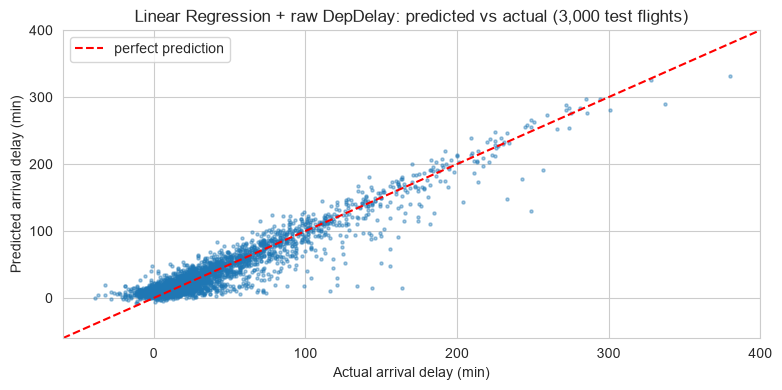

In [22]:
lin = LinearRegression().fit(X_train_reg, y_train_min)
lin_pred = lin.predict(X_test_reg)
print('Linear Regression + raw DepDelay on test -> MAE:', round(mean_absolute_error(y_test_min, lin_pred), 2),
      '| RMSE:', round(mean_squared_error(y_test_min, lin_pred) ** 0.5, 2), '| R2:', round(r2_score(y_test_min, lin_pred), 3))
print('Baseline (arr = dep delay) on test        -> MAE:', round(mean_absolute_error(y_test_min, test_details['DepDelay']), 2))

sample = np.random.default_rng(0).choice(len(y_test_min), 3000, replace=False)
plt.scatter(y_test_min.iloc[sample], lin_pred[sample], s=5, alpha=0.4)
plt.plot([-60, 400], [-60, 400], 'r--', label='perfect prediction')
plt.xlim(-60, 400)
plt.ylim(-60, 400)
plt.xlabel('Actual arrival delay (min)')
plt.ylabel('Predicted arrival delay (min)')
plt.title('Linear Regression + raw DepDelay: predicted vs actual (3,000 test flights)')
plt.legend()
plt.show()

**Result after the fix:** Linear Regression with the raw departure delay is now the **best regression model** (average error about 11.1 minutes, R² about 0.91). It beats both the "arrival = departure" baseline and the Random Forest. The scatter plot shows most flights close to the red line. The biggest misses are flights with very long delays, which are rare and hard to predict.

**Lesson:** a transformation that helps one question (the log for "late or not") can hurt another question (minutes late). The preprocessing has to match the model and the question.

**Honest note:** the gain over the baseline is small (about 0.4 minutes on the test set: 11.2 vs 11.6). The departure delay already tells us most of the arrival delay. The other inputs mainly tell us whether the plane will gain or lose a few extra minutes.

## 13. Example predictions

**Why:** this is what the model's output would look like for a dispatch team: each flight with its probability of arriving 15+ minutes late.

In [23]:
examples = test_details.copy()
examples['prob_delayed_%'] = (test_prob * 100).round(1)
examples['predicted'] = np.where(test_pred == 1, 'delayed', 'not delayed')
examples['actual'] = np.where(y_test.values == 1, 'delayed', 'not delayed')
examples['actual_arr_delay'] = y_test_min.values
examples.drop(columns=['FlightID']).sample(10, random_state=7)

,DepDelay,UniqueCarrier,Origin,DepHour,prob_delayed_%,predicted,actual,actual_arr_delay
14356,29,FL,ATL,21,86.4,delayed,delayed,46.0
3439,9,WN,HOU,13,13.8,not delayed,not delayed,6.0
12153,96,XE,BNA,12,99.2,delayed,delayed,113.0
15029,14,EV,CRW,13,41.6,not delayed,not delayed,9.0
18549,22,DL,SLC,8,81.6,delayed,delayed,25.0
15762,12,FL,ATL,10,37.3,not delayed,not delayed,-5.0
12313,11,AA,DCA,15,28.5,not delayed,not delayed,-4.0
16034,68,FL,TPA,15,98.7,delayed,delayed,77.0
11496,144,UA,SFO,15,99.8,delayed,delayed,158.0
5653,55,EV,PIT,8,97.3,delayed,delayed,37.0


## 14. Challenges, limitations and next steps

**Challenges we ran into**
- **Only late departures in the data.** The Kaggle file keeps only flights that left 6+ minutes late. So our model answers "will a late departure arrive late?", and it is not meant for flights that leave on time. We designed the whole project around this question instead of hiding it.
- **Leakage was everywhere.** Many columns (delay causes, taxi times, actual times) are only known after the flight. We removed them in Milestone 3 and checked that no input is suspiciously close to the target.
- **Size.** With 1.9 million flights, KNN and cross-validation were too slow on a laptop, so we used a random sample of 100,000 flights. The learning curve shows this was enough for Logistic Regression.
- **The log transform helped classification but hurt linear regression** (section 12). We found it by comparing with a baseline, and fixed it.

**Limitations of the final model**
- It improves on the simple departure-delay rule by only about 1.3 accuracy points. Most of its power comes from one input.
- It is weakest for flights that left 10-30 minutes late, which is exactly where a prediction would be most useful.
- The train/test split is random, so flights from the same day can be in both sets. A model used in real life always predicts *future* days, so the real accuracy could be a bit lower.
- The weights show associations, not causes.

**Planned improvements before Demo Day / future work**
1. **Time-based split:** train on January-September and test on October-December, to check the model on truly "future" flights.
2. **Previous-flight feature (domino effect):** use `TailNum` and the scheduled times to find how late the *same aircraft's previous flight* was. That is known before departure and should help the 10-30 minute cases.
3. **Weather data** for the origin and destination airports (from a weather API).
4. **SHAP explanations** for the Random Forest, to compare its explanations with the Logistic Regression ones.
5. **Choose the alarm threshold with the business:** the model gives probabilities, so the airline can trade missed delays against false alarms (for example, only act above 80%).
6. Try a model that predicts the **main delay cause** (late aircraft, carrier, NAS, weather), using the cause columns as the target, which fits the "explain why" goal even better.